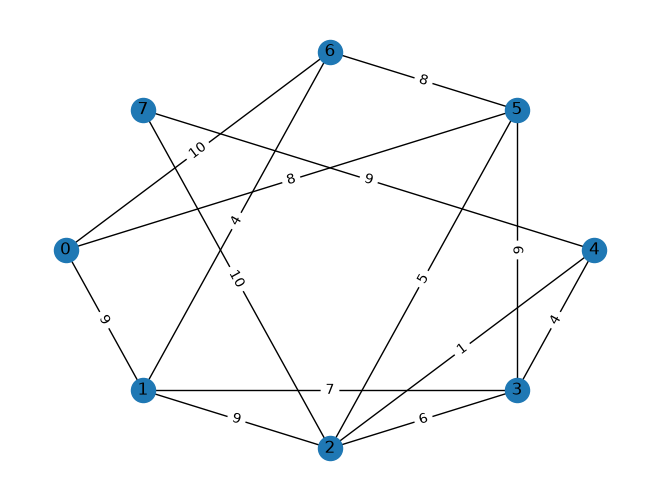

In [1]:
import networkx as nx
import random
import matplotlib.pyplot as plt

# grafo de n nodos donde la probabilidad de que un eje exista es de p
n = 8
G = nx.complete_graph(n)
for (u, v) in G.edges:
  if random.random() < 0.7:
    G.remove_edge(u, v)

for (u, v, w) in G.edges(data=True):
    w['weight'] = random.randint(0, 10)

edge_labels = nx.get_edge_attributes(G, 'weight')
label = nx.nodes(G)
nx.draw_shell(G, with_labels=True,)
nx.draw_networkx_edge_labels(G, nx.shell_layout(G), edge_labels= edge_labels)
plt.show()

In [21]:
# Función para recorrer en profundidad
def dfs(nodo, visitados):
    visitados.add(nodo)
    print(nodo)

    for vecino in  G.neighbors(nodo):
        if vecino not in visitados:
            dfs(vecino,visitados)

dfs(3,set())

3
1
0
4
5
2
6
7


In [ ]:
def recorrer_en_anchura(G, nodo_inicio):
    fila = [nodo_inicio]  
    visitados = []        
    
    while len(fila) > 0:
        nodo_actual = fila.pop(0) 
        print(nodo_actual) 
        if nodo_actual not in visitados:
            visitados.append(nodo_actual)  
            
            # Revisamos sus vecinos
            for vecino in G[nodo_actual]:
                if vecino not in visitados:
                    fila.append(vecino)   
                    
    return visitados
recorrer_en_anchura(G, 0)

[0, 1, 5, 6, 2, 3, 4, 7]

In [ ]:
def recorrido_anchura_voraz(G : nx.Graph, start) :
    por_recorrer = [start]
    recorridos = []
    while por_recorrer:
        actual = por_recorrer.pop(0)
        recorridos.append(actual)
        adyacentes = []
        for arista in sorted(G.edges(data=True), key = lambda a : a[2]['weight']):
            if arista[0] == actual and arista[1] not in recorridos and arista[1] not in por_recorrer:
                adyacentes.append(arista[1])
            elif arista[1] == actual and arista[0] not in recorridos and arista[0] not in por_recorrer:
                adyacentes.append(arista[0])
        #adyacentes = [ady[1] for ady in G.edges if ady[0] == actual and ady[1] not in recorridos and ady[1] not in por_recorrer]
        print(actual)

        for ady in adyacentes:
            por_recorrer.append(ady)

recorrido_anchura_voraz(G, 2)


2
5
1
3
4
6
0
7
